Dataset loaded successfully!
Shape: (10998, 6)


,pH,humidity,temperature,moisture,ldr_status,pump_status
0,5.936350,71.907228,29.831104,72.629549,1,0
1,7.376786,62.964623,32.622037,74.430346,1,1
2,6.829985,88.224926,24.263598,42.702339,1,1
3,6.496646,50.948923,20.783575,33.897843,1,1
4,5.390047,69.392821,21.376931,31.499663,1,1


Target column: pump_status
Using 5 numeric features: ['pH', 'humidity', 'temperature', 'moisture', 'ldr_status']
Train shape: (8798, 5)  Test shape: (2200, 5)


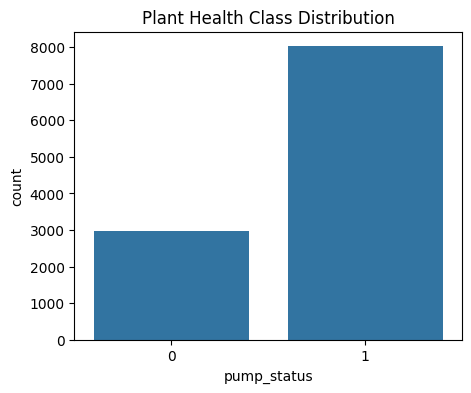

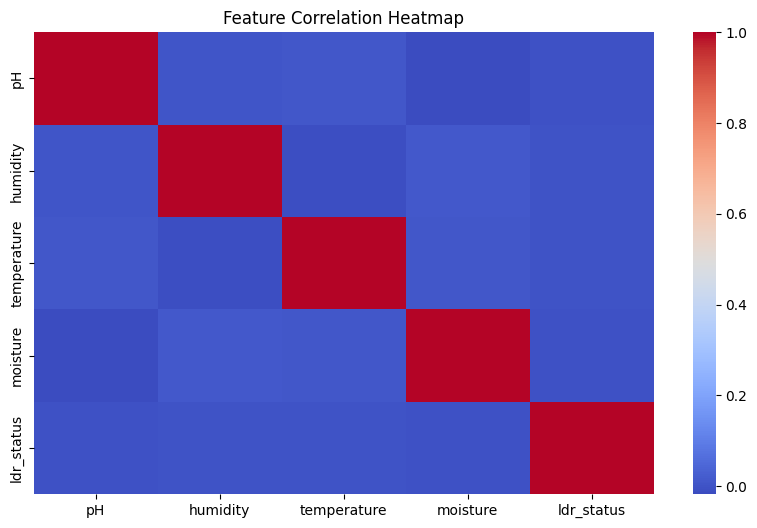

✅ Logistic Regression trained successfully.
✅ Random Forest trained successfully.
✅ KNN trained successfully.

Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.28      0.36       596
           1       0.77      0.89      0.83      1604

    accuracy                           0.73      2200
   macro avg       0.63      0.59      0.59      2200
weighted avg       0.69      0.73      0.70      2200



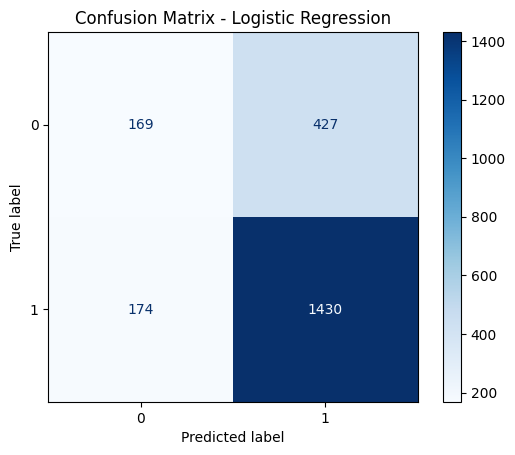


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       596
           1       0.99      0.99      0.99      1604

    accuracy                           0.98      2200
   macro avg       0.97      0.98      0.98      2200
weighted avg       0.98      0.98      0.98      2200



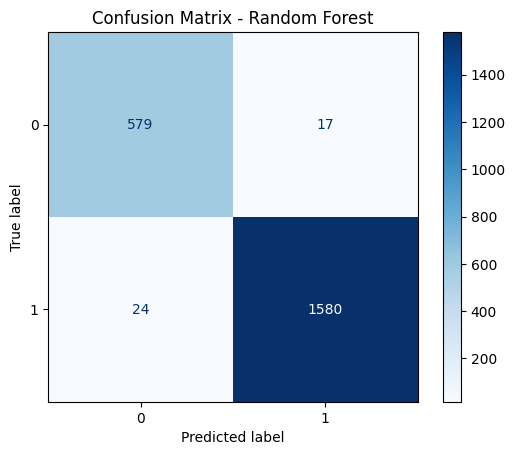


Model: KNN

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       596
           1       0.97      0.97      0.97      1604

    accuracy                           0.95      2200
   macro avg       0.94      0.94      0.94      2200
weighted avg       0.95      0.95      0.95      2200



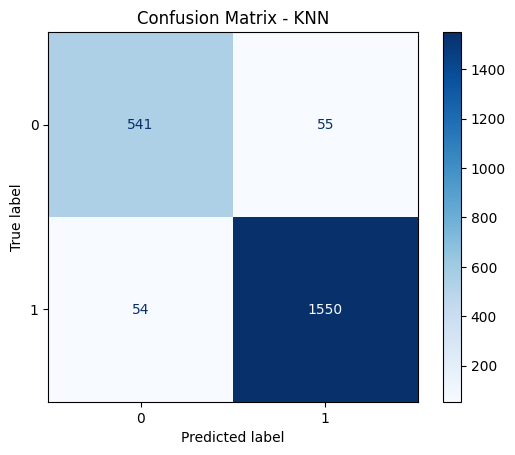

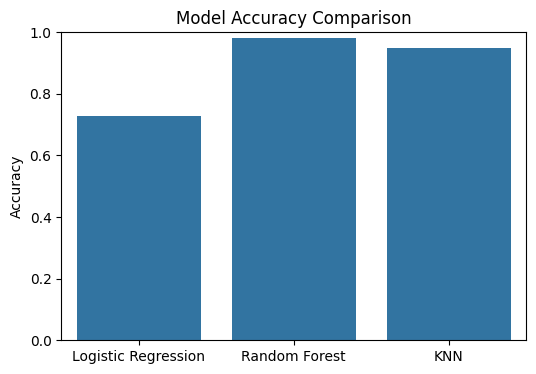


✅ Models and preprocessors saved as .pkl files!


In [1]:

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

import joblib

#%%
# 1️⃣ Load Dataset
file_path = "dataset_hydrophonic.csv"  # Change if necessary
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

#%%
# 2️⃣ Clean & Identify Columns

df.columns = [c.strip() for c in df.columns]

# Detect target column
target_col = "pump_status"#[c for c in df.columns if "Pump" in c and "Status" in c][0]
print("Target column:", target_col)

# Replace missing value markers
df.replace(["?", "NA", "N/A", "--", ""], np.nan, inplace=True)

#%%
# 3️⃣ Clean Numeric Columns
# Convert numeric-like text columns to proper floats
def clean_numeric_column(series):
    series = series.astype(str).str.replace(",", ".", regex=False)
    series = series.str.replace(":", ".", regex=False)
    return pd.to_numeric(series, errors="coerce")

for col in df.columns:
    if col != target_col:
        try:
            df[col] = clean_numeric_column(df[col])
        except Exception:
            pass  # keep non-numeric as is

# Drop non-numeric columns (e.g. timestamps or text)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if target_col in numeric_cols:
    numeric_cols.remove(target_col)

X = df[numeric_cols].copy()
y = df[target_col]

print(f"Using {len(numeric_cols)} numeric features:", numeric_cols)

#%%
# 4️⃣ Encode & Scale

# Label encode target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y.astype(str))

# Impute missing numeric values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

#%%
# 5️⃣ Visualization

plt.figure(figsize=(5,4))
sns.countplot(x=y)
plt.title("Plant Health Class Distribution")
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(pd.DataFrame(X, columns=numeric_cols).corr(), cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

#%%
# 6️⃣ Model Training

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=1, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"✅ {name} trained successfully.")

#%%
# 7️⃣ Evaluation

results = {}

for name, model in trained_models.items():
    print(f"\n{'='*60}")
    print(f"Model: {name}")
    y_pred = model.predict(X_test)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))
    
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.show()
    
    results[name] = model.score(X_test, y_test)

#%%
# 8️⃣ Compare Accuracy

plt.figure(figsize=(6,4))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

#%%
# 9️⃣ Save Models and Preprocessors

joblib.dump(trained_models["Logistic Regression"], "logistic_model.pkl")
joblib.dump(trained_models["Random Forest"], "randomforest_model.pkl")
joblib.dump(trained_models["KNN"], "knn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")
joblib.dump(imputer, "imputer.pkl")

print("\n✅ Models and preprocessors saved as .pkl files!")
